## Persistent Homology for Logistic and FHN Models:


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import gudhi
from gudhi import plot_persistence_barcode, plot_persistence_diagram
import sys
from pathlib import Path
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from src.keller_segel_excitable import KellerSegelExcitable

In [4]:
sim = KellerSegelExcitable(N=256, du=0.05, dv=0.1, CHI=2.0, CAP=2.0, ALPHA=0.1, BETA=0.2, dt=0.05, dx=0.5)
history = sim.run(n_steps=10000, save_every=1000)
steps, us, vs = zip(*history)

output_path = (
    project_root
    / "data"
    / "runs"
    / "snapshots_homology"
    / "KSE_5x10000_steps.npz"
)
output_path.parent.mkdir(parents=True, exist_ok=True)

np.savez(output_path, step=np.asarray(steps, dtype=object), u=np.asarray(us, dtype=object), v=np.asarray(vs, dtype=object))

c:\Users\zekem\Documents\keller-segel-phase-transitions\venv\Lib\site-packages\gudhi\persistence_graphical_tools.py:128: UserWarning: There are 20210 intervals given as input, whereas max_intervals is set to 20000.
  warnings.warn(


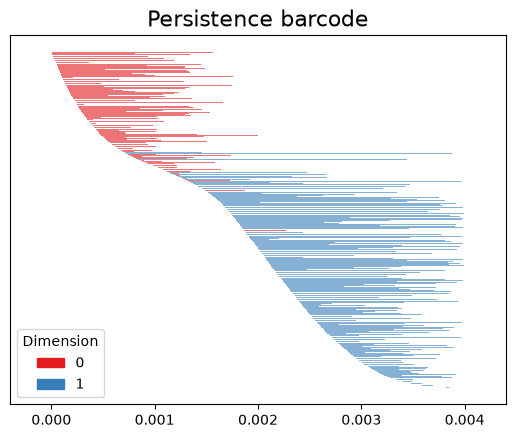

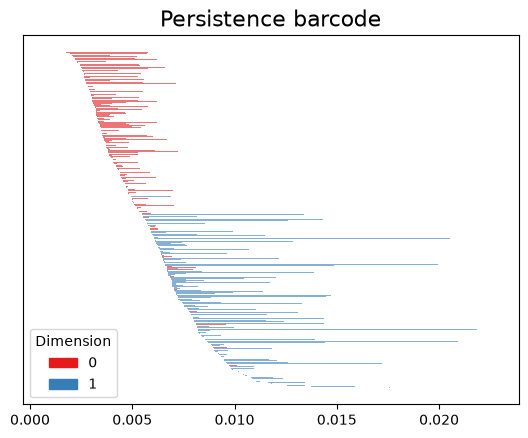

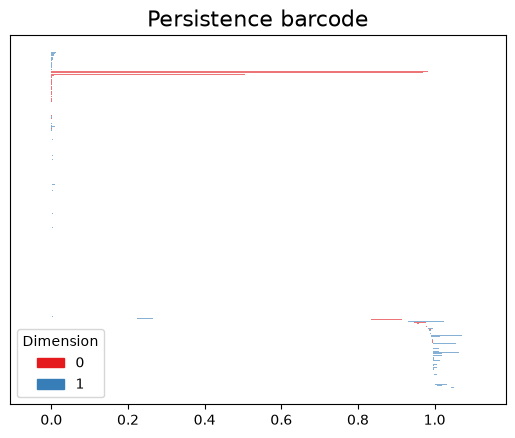

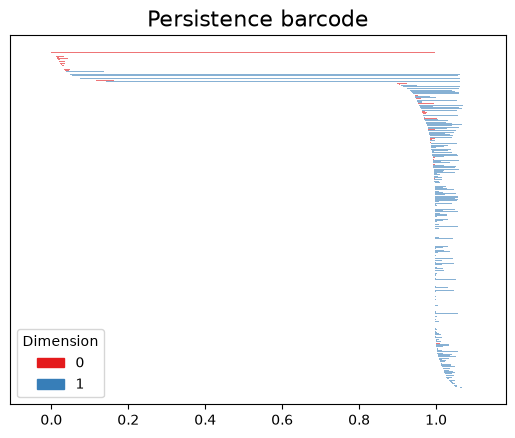

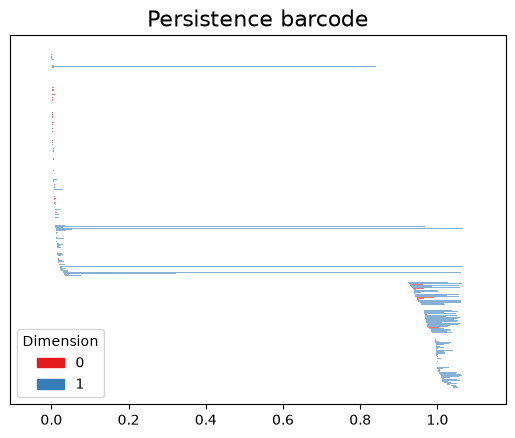

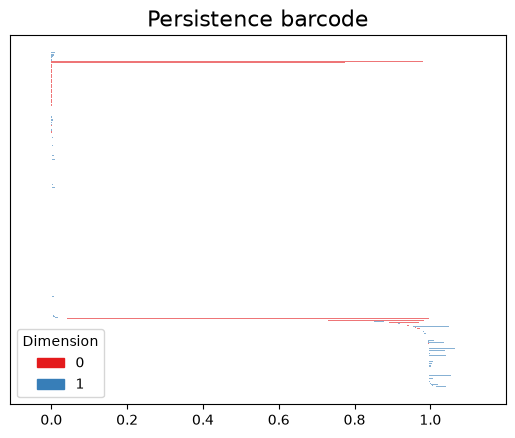

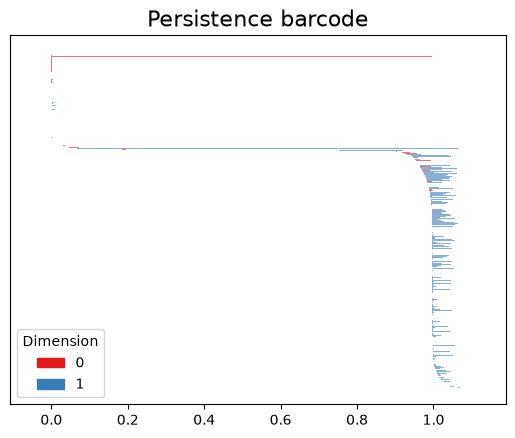

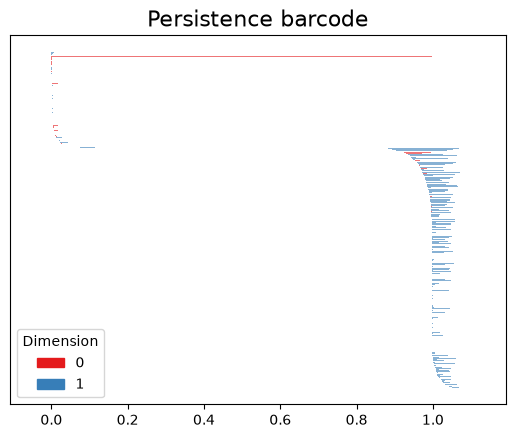

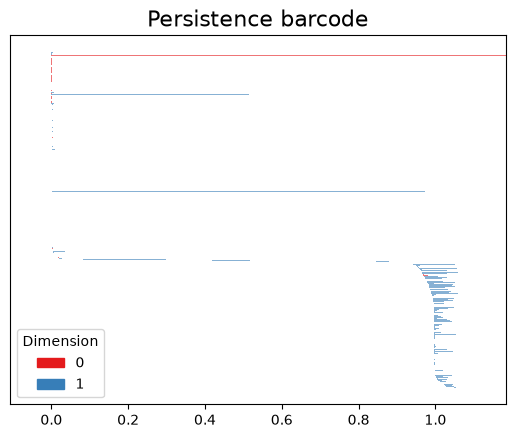

In [16]:
with np.load(output_path, allow_pickle=True) as data:
    step1 = data['step']
    u1 = data['u']
    v1 = data['v']

for i in range(0, 9):
    density_field = np.asarray(v1[i], dtype=float)
    cc = gudhi.CubicalComplex(top_dimensional_cells=density_field)
    cc.compute_persistence()
    
    persistence = cc.persistence() 
    plot_persistence_barcode(persistence)
    plt.show()